<a href="https://colab.research.google.com/github/sofilukash/math_modeling/blob/main/task1_lissajous_chebyshev.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 1. Завдання 1
## Фігури Лісажу та поліном Чебишева

**Мета:** побудувати фігури Лісажу

$$x=\cos(\omega_1 t+\varphi_1),\qquad y=\cos(\omega_2 t+\varphi_2)$$

1-го рангу ($\omega_1/\omega_2=1$) і 2-го рангу ($\omega_1/\omega_2=2$), показати вплив різниці фаз
$\Delta\varphi$, розглянути випадок $\omega_1/\omega_2\neq 1$ (раціональні та ірраціональні відношення),
а також побудувати графік полінома Чебишева $T_n(x)=\cos(n\arccos x)$, $3\le n\le 7$.

**Бібліотеки:** `numpy` (обчислення), `matplotlib` (графіки).
Усі малюнки зберігаються у папку `results/` (для звіту).

In [8]:
import os
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

SAVE_DIR = "results"
os.makedirs(SAVE_DIR, exist_ok=True)

# Підписи кутів π·k/4 у форматі LaTeX (для заголовків графіків)
PHASE_LABELS = ["0", r"\pi/4", r"\pi/2", r"3\pi/4", r"\pi", r"5\pi/4", r"3\pi/2", r"7\pi/4"]


def save(fig, name):
    """Зберегти малюнок у results/ (для звіту)."""
    path = os.path.join(SAVE_DIR, name)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"[збережено] {path}")


def lissajous(w1, w2, phi1, phi2, t):
    """Параметрична крива Лісажу: x = cos(w1*t+phi1), y = cos(w2*t+phi2)."""
    return np.cos(w1 * t + phi1), np.cos(w2 * t + phi2)


def draw(ax, x, y, title, lw=1.6):
    """Намалювати одну фігуру в квадраті [-1, 1]x[-1, 1]; червона точка — початок руху (t = 0)."""
    ax.plot(x, y, lw=lw)
    ax.plot(x[0], y[0], "o", ms=4, color="tab:red")
    ax.set_aspect("equal")
    ax.set_xlim(-1.15, 1.15)
    ax.set_ylim(-1.15, 1.15)
    ax.set_xticks([-1, 0, 1])
    ax.set_yticks([-1, 0, 1])
    ax.set_title(title, fontsize=10)

## 1. Фігури 1-го рангу: $\omega_1/\omega_2 = 1$

Беремо $x=\cos t$, $y=\cos(t+\Delta\varphi)$ і змінюємо $\Delta\varphi$ від $0$ до $7\pi/4$ з кроком $\pi/4$.

З рівнянь виключаємо $t$:
$x^2+y^2-2xy\cos\Delta\varphi=\sin^2\Delta\varphi$ — це **еліпс** з півосями
$a=\sqrt{1+|\cos\Delta\varphi|}$, $b=\sqrt{1-|\cos\Delta\varphi|}$ (вісь вздовж $y=x$ при $\cos\Delta\varphi>0$
і вздовж $y=-x$ при $\cos\Delta\varphi<0$). Звідси всі окремі випадки.

[збережено] results/fig1_lissajous_rank1.png


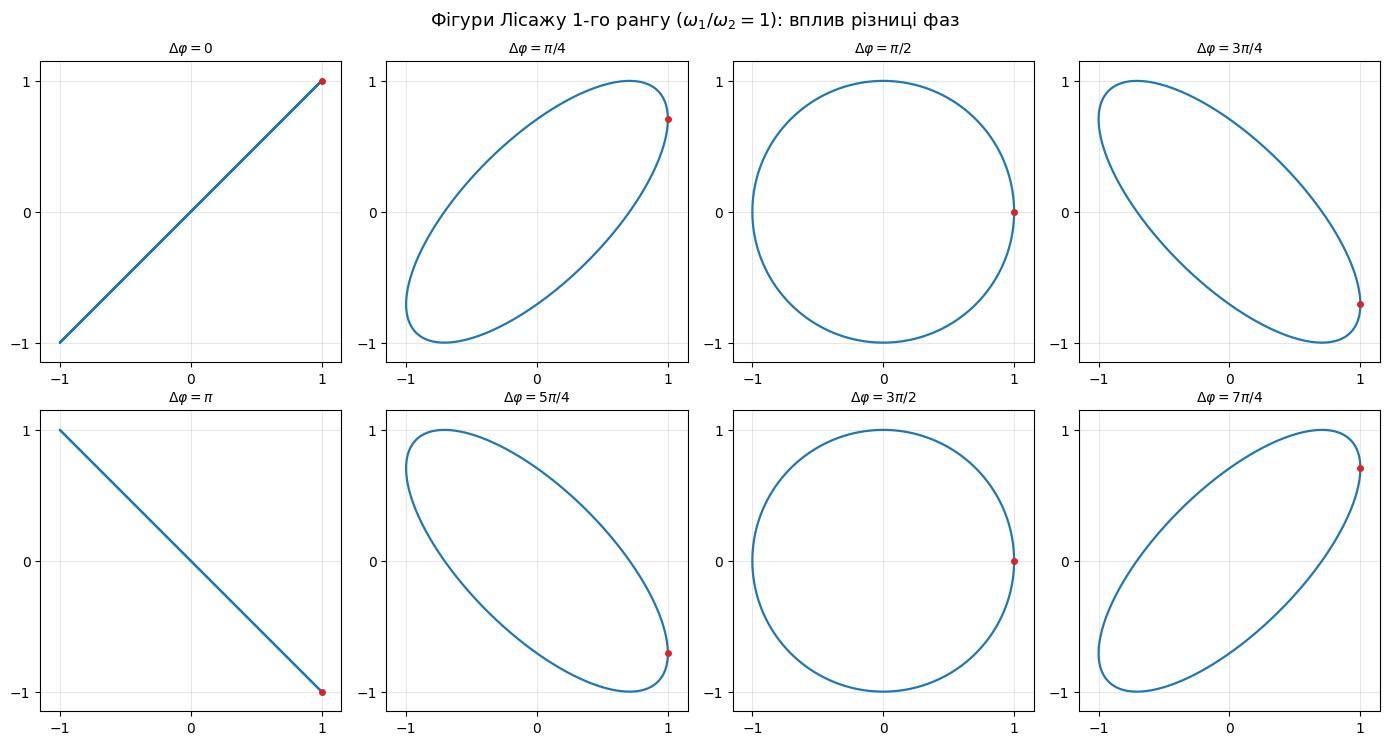

In [9]:
t = np.linspace(0, 2 * np.pi, 2000)

fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for k, ax in enumerate(axes.ravel()):
    dphi = k * np.pi / 4
    x, y = lissajous(1, 1, 0, dphi, t)
    draw(ax, x, y, rf"$\Delta\varphi={PHASE_LABELS[k]}$")
fig.suptitle(r"Фігури Лісажу 1-го рангу ($\omega_1/\omega_2=1$): вплив різниці фаз", fontsize=13)
fig.tight_layout()
save(fig, "fig1_lissajous_rank1.png")
plt.show()

### Характеристика змін (таблиця + перевірка формул півосей чисельно)

In [10]:
def classify_rank1(dphi):
    """Тип фігури 1-го рангу за теорією (півосі a, b; напрям обходу)."""
    c, s = np.cos(dphi), np.sin(dphi)
    a, b = np.sqrt(1 + abs(c)), np.sqrt(1 - abs(c))
    if abs(s) < 1e-9:
        kind = "відрізок прямої " + ("y = x" if c > 0 else "y = -x")
    elif abs(c) < 1e-9:
        kind = "коло"
    else:
        kind = "еліпс, велика вісь вздовж " + ("y = x" if c > 0 else "y = -x")
    return kind, a, b


print(f"{'Δφ':>6} | {'вигляд фігури':<40} | {'a (теор/числ)':>15} | {'b (теор/числ)':>15} | обхід")
print("-" * 100)
for k in range(8):
    dphi = k * np.pi / 4
    kind, a, b = classify_rank1(dphi)
    x, y = lissajous(1, 1, 0, dphi, t)
    r = np.hypot(x, y)  # відстань від центру: max = велика піввісь, min = мала піввісь
    area = 0.5 * np.sum(x[:-1] * np.diff(y) - y[:-1] * np.diff(x))  # орієнтована площа
    if abs(area) < 1e-6:
        direction = "— (відрізок)"
    else:
        direction = "проти годинникової" if area > 0 else "за годинниковою"
    # допуск 5e-3: для відрізка мінімум r=0 потрапляє між вузлами сітки по t
    assert abs(r.max() - a) < 5e-3 and abs(r.min() - b) < 5e-3, "формула півосей не збіглась!"
    print(f"{PHASE_LABELS[k].replace(chr(92), ''):>6} | {kind:<40} | {a:6.3f} / {r.max():6.3f} | "
          f"{b:6.3f} / {r.min():6.3f} | {direction}")
print("\nФормули півосей a=√(1+|cosΔφ|), b=√(1−|cosΔφ|) підтверджені чисельно.")

    Δφ | вигляд фігури                            |   a (теор/числ) |   b (теор/числ) | обхід
----------------------------------------------------------------------------------------------------
     0 | відрізок прямої y = x                    |  1.414 /  1.414 |  0.000 /  0.001 | — (відрізок)
  pi/4 | еліпс, велика вісь вздовж y = x          |  1.307 /  1.307 |  0.541 /  0.541 | за годинниковою
  pi/2 | коло                                     |  1.000 /  1.000 |  1.000 /  1.000 | за годинниковою
 3pi/4 | еліпс, велика вісь вздовж y = -x         |  1.307 /  1.307 |  0.541 /  0.541 | за годинниковою
    pi | відрізок прямої y = -x                   |  1.414 /  1.414 |  0.000 /  0.001 | — (відрізок)
 5pi/4 | еліпс, велика вісь вздовж y = -x         |  1.307 /  1.307 |  0.541 /  0.541 | проти годинникової
 3pi/2 | коло                                     |  1.000 /  1.000 |  1.000 /  1.000 | проти годинникової
 7pi/4 | еліпс, велика вісь вздовж y = x          |  1.307 /  1.307 |  0.541 

## 2. Що буде при $\omega_1/\omega_2 \neq 1$ (раціональні відношення)

Нехай $\omega_1:\omega_2=p:q$ (взаємно прості числа). Крива **замкнена**, період $T=2\pi$ (при $\omega_2=q$, $\omega_1=p$).
Фігура вписана в квадрат; вона торкається вертикальних сторін $p$ разів, горизонтальних — $q$ разів.
При $\Delta\varphi$, для якого рух «збігається» (напр. $0$), фігура вироджується: крива проходиться
туди й назад (відкрита дуга типу $T_n$), при інших фазах з'являються петлі.

[збережено] results/fig2_lissajous_ratio_not1.png


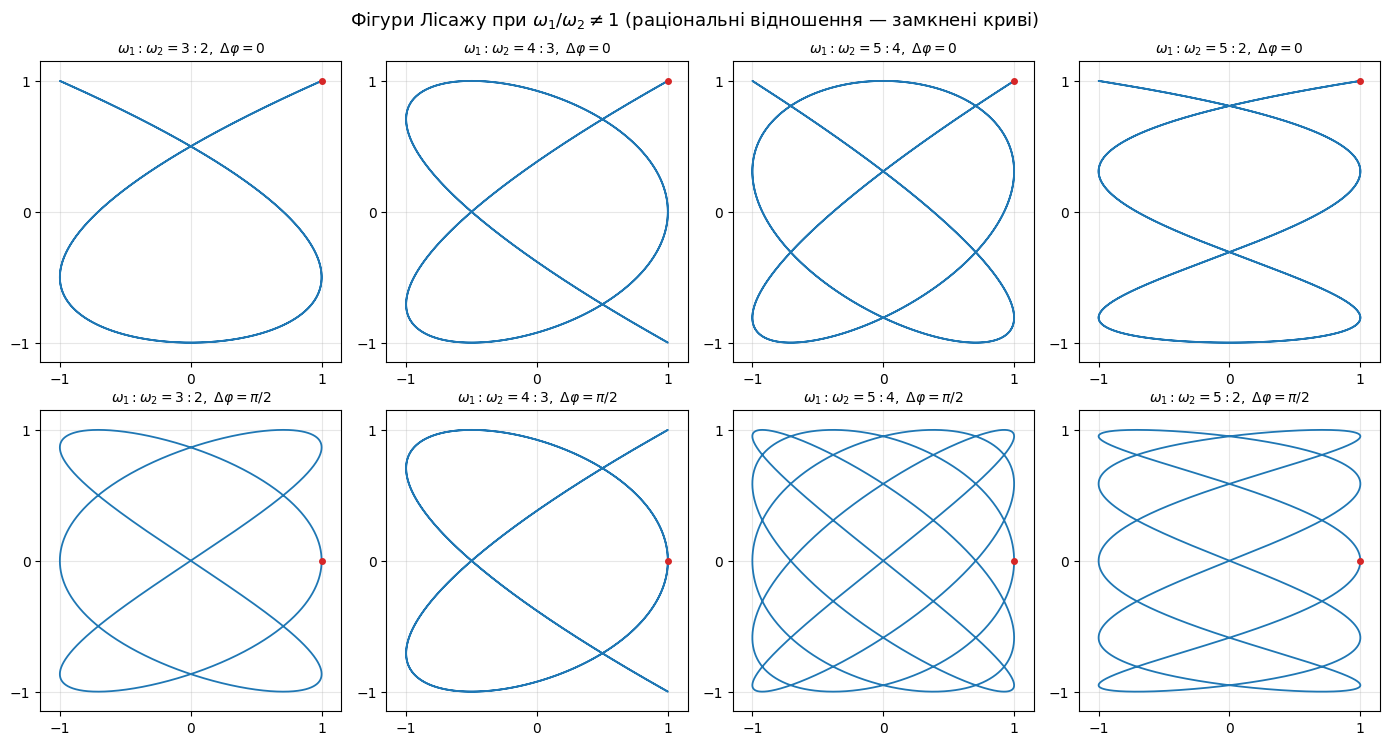

In [11]:
ratios = [(3, 2), (4, 3), (5, 4), (5, 2)]
t = np.linspace(0, 2 * np.pi, 6000)

fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for col, (p, q) in enumerate(ratios):
    for row, (dphi, lab) in enumerate([(0.0, "0"), (np.pi / 2, r"\pi/2")]):
        x, y = lissajous(p, q, 0, dphi, t)
        draw(axes[row, col], x, y, rf"$\omega_1:\omega_2={p}:{q},\ \Delta\varphi={lab}$", lw=1.3)
fig.suptitle(r"Фігури Лісажу при $\omega_1/\omega_2\neq 1$ (раціональні відношення — замкнені криві)", fontsize=13)
fig.tight_layout()
save(fig, "fig2_lissajous_ratio_not1.png")
plt.show()

## 3. Раціональне та ірраціональне відношення частот (контрольне питання 1.5.1)

* $\omega_1/\omega_2$ **раціональне** → крива замкнена (повторюється через період).
* $\omega_1/\omega_2$ **ірраціональне** ($\sqrt2$) → крива **ніколи не замикається** і з часом
  щільно заповнює весь квадрат $[-1,1]\times[-1,1]$.

[збережено] results/fig3_lissajous_irrational.png


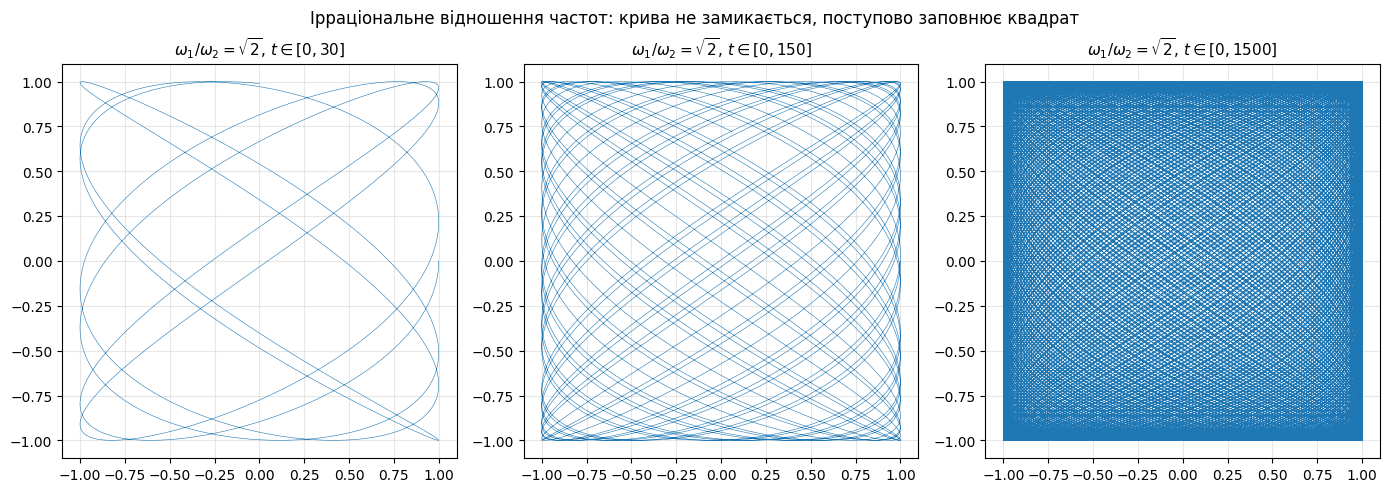

In [12]:
w1, w2 = np.sqrt(2), 1.0
horizons = [30, 150, 1500]  # тривалість моделювання T

fig, axes = plt.subplots(1, 3, figsize=(14, 4.9))
for ax, T in zip(axes, horizons):
    tt = np.arange(0, T, 0.01)
    x, y = lissajous(w1, w2, 0, np.pi / 2, tt)
    ax.plot(x, y, lw=0.4)
    ax.set_aspect("equal")
    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-1.1, 1.1)
    ax.set_title(rf"$\omega_1/\omega_2=\sqrt{{2}}$, $t\in[0,{T}]$", fontsize=11)
fig.suptitle("Ірраціональне відношення частот: крива не замикається, поступово заповнює квадрат", fontsize=12)
fig.tight_layout()
save(fig, "fig3_lissajous_irrational.png")
plt.show()

## 4. Фігури 2-го рангу: $\omega_1/\omega_2 = 2$

$x=\cos(2t+\Delta\varphi)$, $y=\cos t$. Форма залежить від $\Delta\varphi$ (точніше, від $\varphi_1-2\varphi_2$):
* $\Delta\varphi=0$: $x=\cos 2t=2y^2-1$ — **парабола** (вироджена, обходиться туди й назад);
* $\Delta\varphi=\pi/2$ (і $3\pi/2$): $x=-\sin 2t$ — **вісімка** (дві симетричні петлі, перетин у центрі);
* $\Delta\varphi=\pi$: $x=-(2y^2-1)$ — парабола, повернута «вниз» (дзеркальна);
* проміжні значення — перехідні форми: парабола поступово «розкривається» у вісімку й назад.

[збережено] results/fig4_lissajous_rank2.png


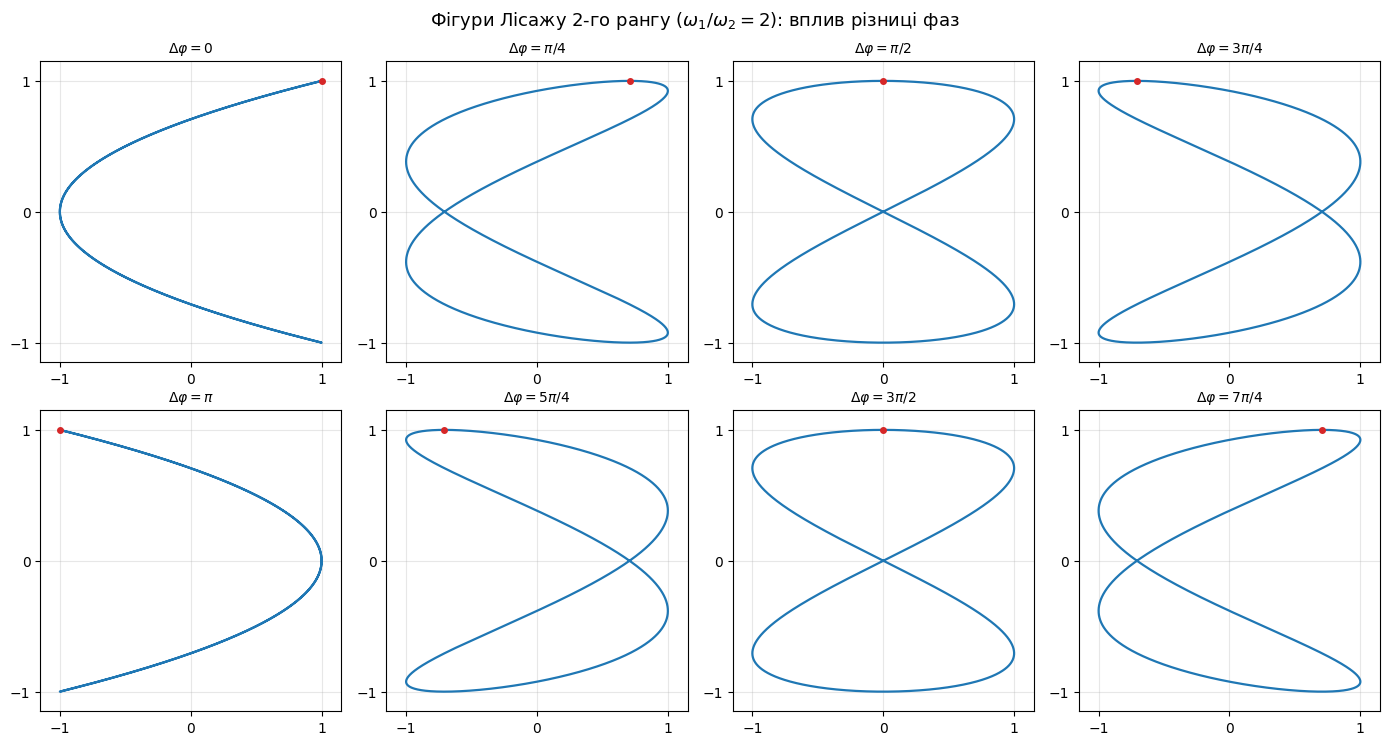

Аналітичні випадки (парабола при Δφ=0, вісімка при Δφ=π/2) підтверджені.


In [13]:
t = np.linspace(0, 2 * np.pi, 4000)

fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for k, ax in enumerate(axes.ravel()):
    dphi = k * np.pi / 4
    x, y = lissajous(2, 1, dphi, 0, t)
    draw(ax, x, y, rf"$\Delta\varphi={PHASE_LABELS[k]}$")
fig.suptitle(r"Фігури Лісажу 2-го рангу ($\omega_1/\omega_2=2$): вплив різниці фаз", fontsize=13)
fig.tight_layout()
save(fig, "fig4_lissajous_rank2.png")
plt.show()

# Перевірка аналітичних випадків
x, y = lissajous(2, 1, 0, 0, t)
assert np.allclose(x, 2 * y**2 - 1), "Δφ=0 має давати параболу x = 2y² − 1"
x, y = lissajous(2, 1, np.pi / 2, 0, t)
assert np.allclose(x, -2 * y * np.sqrt(1 - y**2) * np.sign(np.sin(t))), "Δφ=π/2 — вісімка"
print("Аналітичні випадки (парабола при Δφ=0, вісімка при Δφ=π/2) підтверджені.")

## 5. Поліном Чебишева $T_n(x)=\cos(n\arccos x)$, $n=5$

Для $n=5$: $T_5(x)=16x^5-20x^3+5x$. Властивості, які видно на графіку:
* на $[-1,1]$ значення лежать у межах $[-1,1]$, є $n$ нулів $x_k=\cos\frac{(2k-1)\pi}{2n}$;
* $n+1$ екстремумів $\pm1$ у точках $x=\cos(k\pi/n)$.

Цікавий зв'язок: фігура Лісажу $x=\cos t,\ y=\cos(nt)$ — це **саме графік** $y=T_n(x)$.

max|T5(def) − (16x⁵−20x³+5x)| = 4.00e-15
max|T5(def) − numpy chebval |  = 2.55e-15
[збережено] results/fig5_chebyshev.png


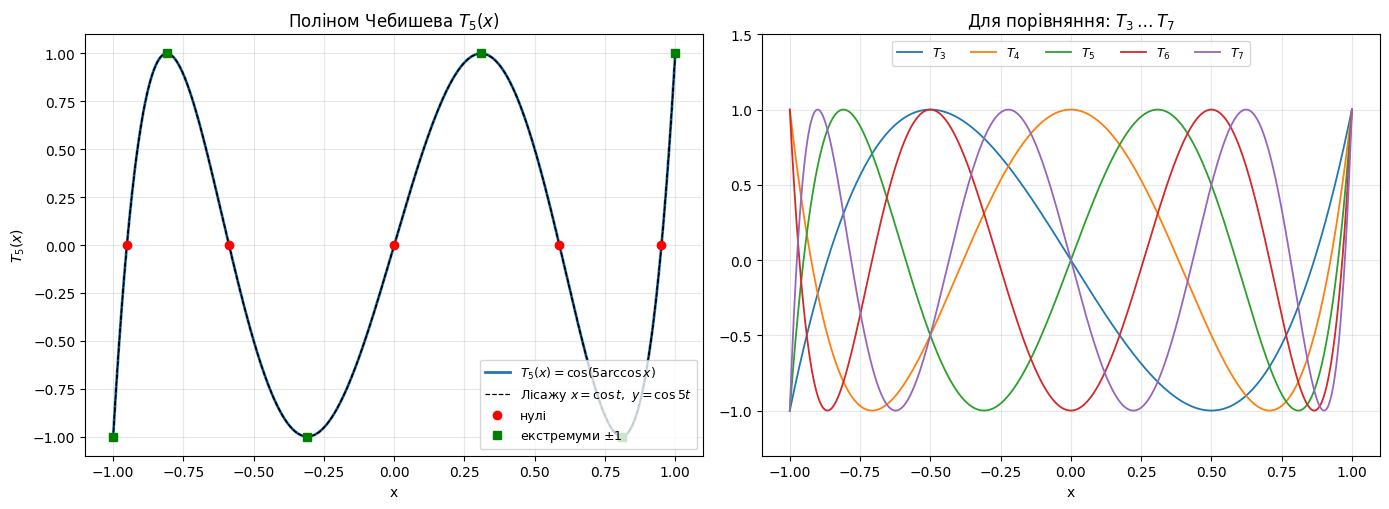

In [14]:
n = 5                                    # порядок полінома (за завданням 3 ≤ n ≤ 7)
xs = np.linspace(-1, 1, 2001)
Tn = np.cos(n * np.arccos(xs))           # означення з методички

# Перевірка: означення = явний поліном = numpy.polynomial.chebyshev
explicit = 16 * xs**5 - 20 * xs**3 + 5 * xs
from_numpy = np.polynomial.chebyshev.chebval(xs, [0] * n + [1])
print(f"max|T5(def) − (16x⁵−20x³+5x)| = {np.max(np.abs(Tn - explicit)):.2e}")
print(f"max|T5(def) − numpy chebval |  = {np.max(np.abs(Tn - from_numpy)):.2e}")

zeros = np.cos((2 * np.arange(1, n + 1) - 1) * np.pi / (2 * n))
extrema = np.cos(np.arange(0, n + 1) * np.pi / n)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

ax1.plot(xs, Tn, lw=2, label=r"$T_5(x)=\cos(5\arccos x)$")
tt = np.linspace(0, 2 * np.pi, 400)
ax1.plot(np.cos(tt), np.cos(n * tt), "k--", lw=0.9, label=r"Лісажу $x=\cos t,\ y=\cos 5t$")
ax1.plot(zeros, np.zeros(n), "ro", label="нулі")
ax1.plot(extrema, np.cos(n * np.arccos(extrema)), "gs", ms=6, label=r"екстремуми $\pm1$")
ax1.set_title(r"Поліном Чебишева $T_5(x)$")
ax1.set_xlabel("x")
ax1.set_ylabel(r"$T_5(x)$")
ax1.legend(loc="lower right", fontsize=9)

for m in range(3, 8):
    ax2.plot(xs, np.cos(m * np.arccos(xs)), lw=1.3, label=rf"$T_{m}$")
ax2.set_title(r"Для порівняння: $T_3 \dots T_7$")
ax2.set_xlabel("x")
ax2.legend(ncol=5, fontsize=9, loc="upper center")
ax2.set_ylim(-1.3, 1.5)

fig.tight_layout()
save(fig, "fig5_chebyshev.png")
plt.show()

## Відповіді на питання та висновки (завдання 1)

**Фігури 1-го рангу** ($\omega_1=\omega_2$). Вигляд визначається лише різницею фаз $\Delta\varphi$:
* $\Delta\varphi=0$ — відрізок прямої $y=x$;
* $0<\Delta\varphi<\pi/2$ — еліпс, витягнутий вздовж $y=x$, обхід за годинниковою стрілкою;
* $\Delta\varphi=\pi/2$ — коло (півосі однакові);
* $\pi/2<\Delta\varphi<\pi$ — еліпс, витягнутий вздовж $y=-x$;
* $\Delta\varphi=\pi$ — відрізок прямої $y=-x$;
* при $\pi<\Delta\varphi<2\pi$ фігури повторюються, але напрям обходу змінюється на протилежний
  (проти годинникової стрілки).

**При $\omega_1/\omega_2\neq1$** (раціональне $p/q$) крива стає складнішою: з'являються петлі, фігура
вписана в квадрат і торкається його вертикальних сторін $p$ разів, горизонтальних — $q$ разів;
при «збігу» фаз крива вироджується в дугу, що обходиться двічі.

**Фігури 2-го рангу** ($\omega_1/\omega_2=2$): при $\Delta\varphi=0,\pi$ — параболи (дзеркальні одна одній),
при $\Delta\varphi=\pi/2,\ 3\pi/2$ — вісімка; проміжні фази дають перехідні форми.

**Контрольне питання 1.5.1.** При раціональному відношенні частот фігура Лісажу — замкнена крива
(повторюється з періодом $T$); при ірраціональному — крива не замикається й з часом щільно заповнює
весь прямокутник.

**Поліном Чебишева** $T_5(x)$ збігається з $16x^5-20x^3+5x$ (похибка ~$10^{-15}$), має 5 нулів і
6 екстремумів $\pm1$ на $[-1,1]$; збігається з кривою Лісажу $x=\cos t,\ y=\cos 5t$.